In [1]:
import numpy as np
from scipy import stats
from scipy.stats import ttest_ind
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Figure 5

## Panel A

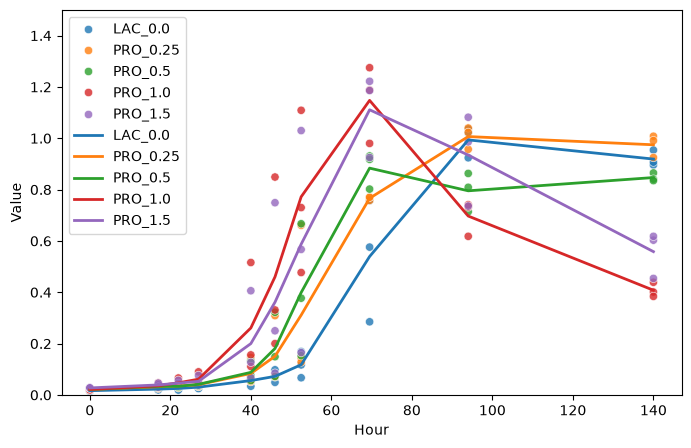

In [2]:
df = pd.read_excel("Figure5.xlsx",sheet_name="OCT_proline")
df["Condition"] = df["Media"] + "_" + df["EA_ED"].astype(str)

plotdata = df[(df["Unit"].isin(["OD600"])) & (df["Condition"]!="PRO_0.0")]

summary = (
    plotdata.groupby(["Condition", "Hour"])["Value"]
    .mean()  
    .reset_index()
)

plt.figure(figsize=(8, 5))
condition_order = sorted(plotdata["Condition"].unique())

# replicates
sns.scatterplot(
    data=plotdata,
    x="Hour",
    y="Value",
    hue="Condition",
    alpha=0.8,
    hue_order=condition_order
)

# average
sns.lineplot(
    data=summary,
    x="Hour",
    y="Value",
    hue="Condition",
    linewidth=2,
    hue_order=condition_order
)
plt.ylim(0, 1.5)
plt.legend()
plt.show()

## Panel B

In [3]:
ID = ["Media", "EA_ED", "Replicate", "Condition"]
COEFF = {"C4n": 2, "C5n": 1, "C6n": 3, "C7n": 2, "C8n": 4} # ACCoA equivalents per metabolite
T_END = 140 # experimental endpoint

df["Condition"] = df["Media"] + "_" + df["EA_ED"].astype(str)

# lactate consumption
lac = (df[df["Unit"] == "Lactate RID"]
       .pivot_table(index=ID, columns="Hour", values="Value"))
consumption = ((lac[0] - lac[T_END]).rename("Value").reset_index()
               .assign(Unit="Lactate Consumption", Hour=T_END))

# acetyl-CoA equivalents at endpoint
end = (df[(df["Hour"] == T_END) & df["Unit"].isin(COEFF)]
       .pivot_table(index=ID, columns="Unit", values="Value"))
accoa = end.mul(pd.Series(COEFF), axis=1)
accoa = accoa.rename(columns={k: f"C{k[1]} as ACCoA" for k in COEFF})

accoa_long = (accoa.reset_index()
              .melt(id_vars=ID, var_name="Unit", value_name="Value")
              .assign(Hour=T_END))

df_combined = pd.concat([df, consumption, accoa_long], ignore_index=True)

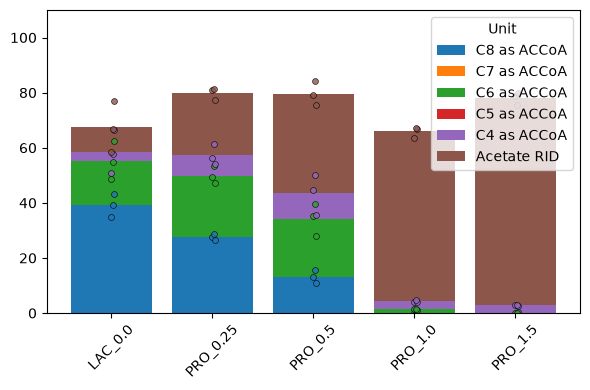

In [4]:
keep = (df_combined["Unit"] == "Acetate RID") | df_combined["Unit"].str.contains("as ACCoA", na=False)

pltdata = df_combined[
    keep
    & (df_combined["Condition"] != "PRO_0.0")
    & (df_combined["Hour"] == 140)
]

# define orders
unit_order = sorted(pltdata["Unit"].dropna().unique(), reverse=True)
cond_order = sorted(pltdata["Condition"].dropna().unique())

# calculate means
means = (
    pltdata
    .groupby(["Condition", "Unit"], as_index=False)["Value"]
    .mean()
)

means["Condition"] = pd.Categorical(means["Condition"], categories=cond_order, ordered=True)
means["Unit"] = pd.Categorical(means["Unit"], categories=unit_order, ordered=True)

means = means.sort_values(["Condition", "Unit"])

# ensure stacked means
means["y1"] = means.groupby("Condition")["Value"].cumsum()
means["y0"] = means["y1"] - means["Value"]

rep_stack = (
    pltdata
    .copy()
)

rep_stack["Condition"] = pd.Categorical(rep_stack["Condition"], categories=cond_order, ordered=True)
rep_stack["Unit"] = pd.Categorical(rep_stack["Unit"], categories=unit_order, ordered=True)

rep_stack = rep_stack.sort_values(["Condition", "Replicate", "Unit"])

# stack within each replicate
rep_stack["y1"] = rep_stack.groupby(["Condition", "Replicate"])["Value"].cumsum()
rep_stack["y0"] = rep_stack["y1"] - rep_stack["Value"]
rep_stack["stack_y"] = rep_stack["y1"]

# set jitter
x_map = {c: i for i, c in enumerate(cond_order)}

means["x"] = means["Condition"].map(x_map).astype(float)
rep_stack["x"] = rep_stack["Condition"].map(x_map).astype(float)

# lock x=axis offset jitter per replicate (keeps vertical stacks aligned)
np.random.seed(42)
rep_offsets = {
    rep: np.random.uniform(-0.03, 0.03)
    for rep in rep_stack["Replicate"].unique()
}

rep_stack["x_jitter"] = rep_stack["x"] + rep_stack["Replicate"].map(rep_offsets)

fig, ax = plt.subplots(figsize=(6, 4))

colors = plt.cm.tab10(range(len(unit_order)))

# stack averages
for i, unit in enumerate(unit_order):
    sub = means[means["Unit"] == unit]
    ax.bar(
        sub["x"],
        sub["Value"],
        bottom=sub["y0"],
        color=colors[i],
        width=0.8,
        label=unit
    )

# stacl replicates
for i, unit in enumerate(unit_order):
    subp = rep_stack[rep_stack["Unit"] == unit]

    ax.scatter(
        subp["x_jitter"].to_numpy(),
        subp["stack_y"].to_numpy(),
        facecolors=colors[i],
        edgecolors="black",
        linewidths=0.5,
        alpha=0.8,
        s=18
    )

# --- axes / legend ---
ax.set_xticks(list(x_map.values()))
ax.set_xticklabels(cond_order, rotation=45)
ax.set_ylim(0, 110)

ax.legend(title="Unit")

plt.tight_layout()
plt.show()

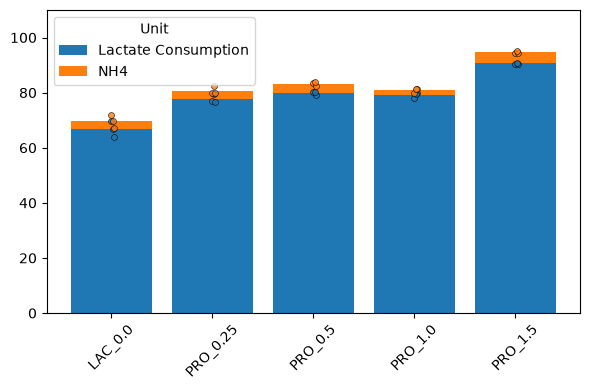

In [5]:
keep = (df_combined["Unit"] == "Lactate Consumption") | (df_combined["Unit"] == "NH4")

pltdata = df_combined[
    keep
    & (df_combined["Condition"] != "PRO_0.0")
    & (df_combined["Hour"] == 140)
]

pltdata["Value"] = pd.to_numeric(pltdata["Value"], errors="coerce")

unit_order = sorted(pltdata["Unit"].dropna().unique(), reverse=False)
cond_order = sorted(pltdata["Condition"].dropna().unique())

means = (
    pltdata
    .groupby(["Condition", "Unit"], as_index=False)["Value"]
    .mean()
)

means["Condition"] = pd.Categorical(means["Condition"], categories=cond_order, ordered=True)
means["Unit"] = pd.Categorical(means["Unit"], categories=unit_order, ordered=True)

means = means.sort_values(["Condition", "Unit"])

# stack means
means["y1"] = means.groupby("Condition")["Value"].cumsum()
means["y0"] = means["y1"] - means["Value"]

rep_stack = (
    pltdata
    .copy()
)

rep_stack["Condition"] = pd.Categorical(rep_stack["Condition"], categories=cond_order, ordered=True)
rep_stack["Unit"] = pd.Categorical(rep_stack["Unit"], categories=unit_order, ordered=True)

rep_stack = rep_stack.sort_values(["Condition", "Replicate", "Unit"])

# stack within each replicate
rep_stack["y1"] = rep_stack.groupby(["Condition", "Replicate"])["Value"].cumsum()
rep_stack["y0"] = rep_stack["y1"] - rep_stack["Value"]
rep_stack["stack_y"] = rep_stack["y1"]

x_map = {c: i for i, c in enumerate(cond_order)}

means["x"] = means["Condition"].map(x_map).astype(float)
rep_stack["x"] = rep_stack["Condition"].map(x_map).astype(float)

# same jitter per replicate (keeps vertical stacks aligned)
np.random.seed(42)
rep_offsets = {
    rep: np.random.uniform(-0.03, 0.03)
    for rep in rep_stack["Replicate"].unique()
}

rep_stack["x_jitter"] = rep_stack["x"] + rep_stack["Replicate"].map(rep_offsets)

fig, ax = plt.subplots(figsize=(6, 4))

colors = plt.cm.tab10(range(len(unit_order)))

for i, unit in enumerate(unit_order):
    sub = means[means["Unit"] == unit]
    ax.bar(
        sub["x"],
        sub["Value"],
        bottom=sub["y0"],
        color=colors[i],
        width=0.8,
        label=unit
    )

for i, unit in enumerate(unit_order):
    subp = rep_stack[rep_stack["Unit"] == unit]

    ax.scatter(
        subp["x_jitter"].to_numpy(),
        subp["stack_y"].to_numpy(),
        facecolors=colors[i],
        edgecolors="black",
        linewidths=0.5,
        alpha=0.8,
        s=18
    )

ax.set_xticks(list(x_map.values()))
ax.set_xticklabels(cond_order, rotation=45)
ax.set_ylim(0, 110)

ax.legend(title="Unit")

plt.tight_layout()
plt.show()

## Panel C

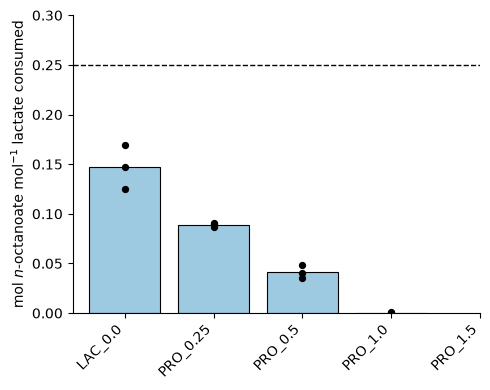

In [6]:
import matplotlib.pyplot as plt

ID = ["Media", "EA_ED", "Replicate", "Condition"]

pltdata = (df_combined[(df_combined["Hour"] == 140)
                       & df_combined["Unit"].isin(["C8n", "Lactate Consumption"])
                       & (df_combined["Condition"] != "PRO_0.0")]
           .pivot_table(index=ID, columns="Unit", values="Value")
           .reset_index())

pltdata["Yield"] = pltdata["C8n"] / pltdata["Lactate Consumption"]

order = (pltdata[["Condition", "EA_ED"]].drop_duplicates()
         .sort_values("EA_ED")["Condition"].tolist())
pltdata["Condition"] = pd.Categorical(pltdata["Condition"], categories=order, ordered=True)
pltdata = pltdata.sort_values("Condition")

means = pltdata.groupby("Condition", observed=True)["Yield"].mean()

fig, ax = plt.subplots(figsize=(5, 4))
x = range(len(means))

ax.bar(x, means, color="#9ecae1", edgecolor="black", linewidth=0.8, zorder=2)

for i, cond in enumerate(means.index):
    pts = pltdata.loc[pltdata["Condition"] == cond, "Yield"]
    ax.scatter([i] * len(pts), pts, color="black", s=18, zorder=3)

ax.axhline(0.25, ls="--", color="black", lw=1, zorder=1)

ax.set_xticks(list(x))
ax.set_xticklabels(means.index, rotation=45, ha="right")
ax.set_ylabel(r"mol $n$-octanoate mol$^{-1}$ lactate consumed")
ax.set_ylim(0, 0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

# Panel D

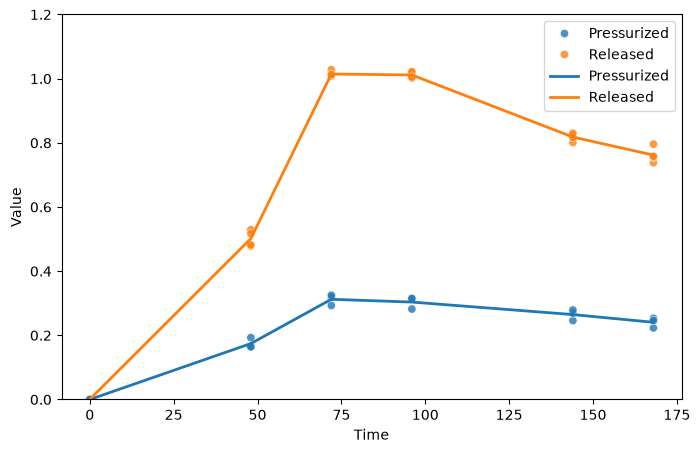

In [7]:
df = pd.read_excel("Figure5.xlsx",sheet_name="OCT_h2co2")
drop = (
     (df["Condition"] == "Pressurized")
    & (df["Replicate"] == "B")
    & (df["Strain"] == "OCT")
)
df=df[~drop]
id_cols = ["Strain", "Condition", "Time", "Replicate"]

long_df = df.melt(
    id_vars=id_cols,
    var_name="Measurement",
    value_name="Value",
)

plotdata = long_df[long_df["Measurement"] == "OD600"]

summary = (
    plotdata.groupby(["Condition", "Time"])["Value"]
    .mean() 
    .reset_index()
)

plt.figure(figsize=(8, 5))
condition_order = sorted(plotdata["Condition"].unique())

# Plot individual points
sns.scatterplot(
    data=plotdata,
    x="Time",
    y="Value",
    hue="Condition",
    alpha=0.8,
    hue_order=condition_order
)

# Plot summary line
sns.lineplot(
    data=summary,
    x="Time",
    y="Value",
    hue="Condition",
    linewidth=2,
    hue_order=condition_order
)
plt.ylim(0, 1.2)
plt.legend()
plt.show()


## Panel E

Lactate and amino acid utilization

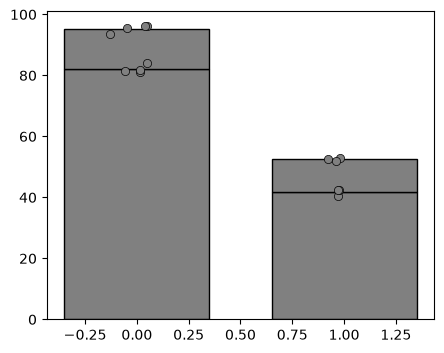

In [8]:
plotdata = long_df[(long_df["Measurement"] == "laccons") | (long_df["Measurement"] == "NH4_increase")].copy()
plotdata = plotdata[(plotdata["Time"]==168)]
drop = (
    (plotdata["Condition"] == "Pressurized")
    & (plotdata["Replicate"] == "B")
)
plotdata = plotdata[~drop]

condition_order = ["Released", "Pressurized"]

summary = (
    plotdata
    .groupby(["Condition", "Measurement"], observed=True)
    .agg(mean_val=("Value", "mean"))
    .reset_index()
)

units = summary["Measurement"].unique()

fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(len(condition_order))

bottoms = np.zeros(len(condition_order))

for unit in units[::-1]:

    sub = (
        summary[summary["Measurement"] == unit]
        .set_index("Condition")
        .reindex(condition_order)
    )

    means = sub["mean_val"].fillna(0).values

    # stacked bar
    ax.bar(
        x,
        means,
        bottom=bottoms,
        label=unit,
        width=0.7,
        edgecolor="black",
        zorder=1,
        color="grey"
    )

    # stacked replicate points
    for i, handling in enumerate(condition_order):

        vals = plotdata.loc[
            (plotdata["Condition"] == handling) &
            (plotdata["Measurement"] == unit),
            "Value"
        ].values

        jitter = np.random.normal(0, 0.05, len(vals))

        ax.scatter(
            np.full(len(vals), x[i]) + jitter,
            bottoms[i] + vals,        # <-- shift upward by stack height
            s=35,
            edgecolor="black",
            linewidth=0.5,
            zorder=3,
            color="grey"
        )

    bottoms = bottoms + means
plt.show()

Transform to C2 units and plot VFAs

In [9]:
exclude = ['OD600', 'psi', 'kpa', 'NH4', 'NH4_increase', 'lactate',
       'laccons', 'Note']
exclusions = '|'.join(exclude)
plotdata = long_df[(~long_df["Measurement"].str.contains(exclusions, na=False))]
plotdata = plotdata[plotdata["Time"]==168]
drop = (
    (plotdata["Condition"] == "Pressurized")
    & (plotdata["Replicate"] == "B")
    & (plotdata["Time"] == 168)
)
plotdata = plotdata[~drop]
condition_order = ["Released","Pressurized"]  
plotdata.loc[plotdata["Measurement"] == "C8n", "Value"] *= 4
plotdata.loc[plotdata["Measurement"] == "C6n", "Value"] *= 3
plotdata.loc[plotdata["Measurement"] == "C4n", "Value"] *= 2

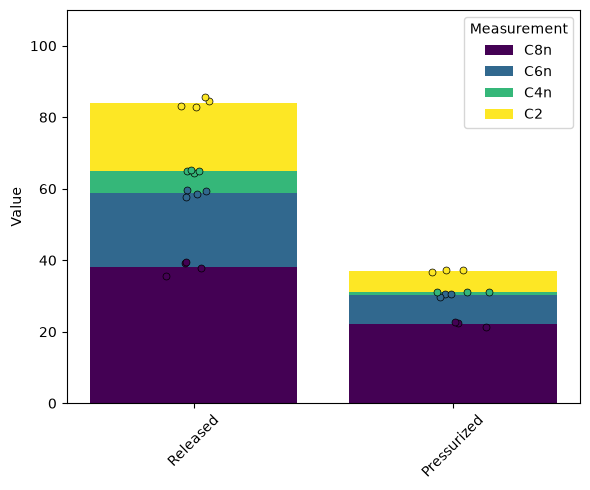

In [ ]:
unit_order = ["C8n", "C6n", "C4n", "C2"]
colors = plt.cm.viridis(np.linspace(0, 1, len(unit_order)))

summary = (
    plotdata.groupby(["Time", "Condition", "Measurement"], as_index=False)["Value"]
    .mean()
)

fig, ax = plt.subplots(figsize=(6, 5))

x = np.arange(len(condition_order))

for hour in summary["Time"].unique():

    df_h = summary[summary["Time"] == hour]
    bottom = np.zeros(len(condition_order))

    for unit, color in zip(unit_order, colors):

        y = (
            df_h[df_h["Measurement"] == unit]
            .set_index("Condition")
            .reindex(condition_order)["Value"]
            .fillna(0)
            .to_numpy()
        )

        ax.bar(
            x, y, bottom=bottom, color=color,
            label=unit if hour == summary["Time"].iat[0] else None
        )

        for j, cond in enumerate(condition_order):

            vals = plotdata.loc[
                (plotdata["Time"] == hour)
                & (plotdata["Condition"] == cond)
                & (plotdata["Measurement"] == unit),
                "Value",
            ]

            ax.scatter(
                np.full(len(vals), x[j]) + np.random.normal(0, 0.05, len(vals)),
                bottom[j] + vals,
                color=color,
                edgecolor="black",
                linewidth=0.5,
                s=25,
                zorder=3,
            )

        bottom = bottom + y

ax.set_xticks(x)
ax.set_xticklabels(condition_order, rotation=45)
ax.set_ylabel("Value")
ax.set_ylim(0, 110)
ax.legend(title="Measurement")

plt.tight_layout()
plt.show()

## Panel F

In [11]:
metabolites = ['C2', 'C4n','C6n','C8n','NH4_increase', 'laccons']
stoichdf = long_df[(long_df["Measurement"].isin(metabolites)) & (long_df["Time"]==168)] 

summary = (
    stoichdf
    .groupby(["Condition", "Measurement"], observed=True)
    .agg(mean_val=("Value", "mean"))
    .reset_index()
)
conditions = summary["Condition"].unique()

for condition in conditions:
    slc = summary[summary["Condition"]==condition]
    laccons= slc[slc["Measurement"]=="laccons"]["mean_val"].iloc[0]
    c2=slc[slc["Measurement"]=="C2"]["mean_val"].iloc[0]/laccons
    c4=slc[slc["Measurement"]=="C4n"]["mean_val"].iloc[0]/laccons
    c6=slc[slc["Measurement"]=="C6n"]["mean_val"].iloc[0]/laccons
    c8=slc[slc["Measurement"]=="C8n"]["mean_val"].iloc[0]/laccons
    amm=slc[slc["Measurement"]=="NH4_increase"]["mean_val"].iloc[0]/laccons
    difference = (1 + amm) - (c2+(2*c4)+(3*c6)+(4*c8))

    print(condition)
    print(f"Lactate + {amm:.2f} Amino Acid -> {c2:.2f} Acetate + {c4:.2f} n-Butanoate + {c6:.2f} n-Hexanoate\n + {c8:.2f} n-Octanoate + {amm:.2f} Ammonium + {amm+1:.2f} CO2")
    print(f"Missing AcCoA: {difference:.2f}\n")

id_cols = ["Strain", "Condition", "Time", "Replicate"]

wide = stoichdf.pivot(
    index=id_cols,
    columns="Measurement",
    values="Value",
)

c8norm = (
    (wide["C8n"] / wide["laccons"])
    .rename("Value")
    .reset_index()
    .assign(Measurement="c8norm")
)

stoichdf = pd.concat([stoichdf, c8norm], ignore_index=True)


Pressurized
Lactate + 0.26 Amino Acid -> 0.14 Acetate + 0.01 n-Butanoate + 0.07 n-Hexanoate
 + 0.13 n-Octanoate + 0.26 Ammonium + 1.26 CO2
Missing AcCoA: 0.37

Released
Lactate + 0.16 Amino Acid -> 0.23 Acetate + 0.04 n-Butanoate + 0.08 n-Hexanoate
 + 0.12 n-Octanoate + 0.16 Ammonium + 1.16 CO2
Missing AcCoA: 0.14



In [12]:
pressurized = c8norm.loc[
    c8norm["Condition"] == "Pressurized", "Value"
]

released = c8norm.loc[
    c8norm["Condition"] == "Released", "Value"
]

stat, p = ttest_ind(
    pressurized,
    released,
    equal_var=False
)

print(f"Welch's t-test: t = {stat:.3f}, p = {p:.4g}")

Welch's t-test: t = 6.187, p = 0.007246


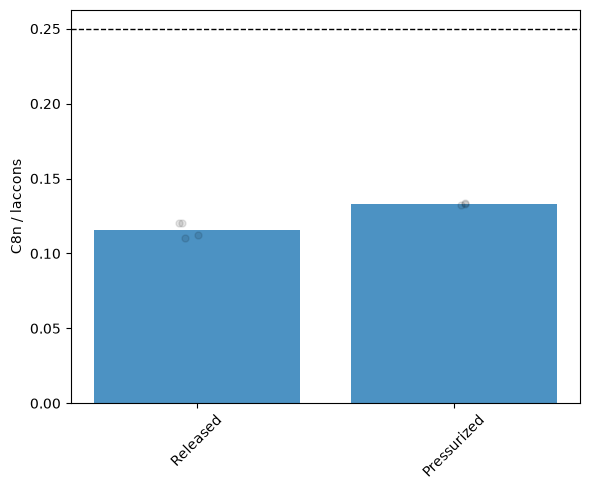

In [13]:
plotdata = stoichdf[stoichdf["Measurement"]=="c8norm"]
condition_order = ["Released", "Pressurized"]

summary = (
    plotdata.groupby(["Time", "Condition"], as_index=False)["Value"]
    .mean()
)

fig, ax = plt.subplots(figsize=(6, 5))

x = np.arange(len(condition_order))

for hour in summary["Time"].unique():

    y = (
        summary[summary["Time"] == hour]
        .set_index("Condition")
        .reindex(condition_order)["Value"]
        .to_numpy()
    )

    ax.bar(x, y, width=0.8, alpha=0.8, label=f"{hour} h")

    for j, cond in enumerate(condition_order):

        vals = plotdata.loc[
            (plotdata["Time"] == hour) &
            (plotdata["Condition"] == cond),
            "Value",
        ]

        ax.scatter(
            np.full(len(vals), x[j]) + np.random.normal(0, 0.05, len(vals)),
            vals,
            color="black",
            s=25,
            zorder=3,
            alpha=0.1
        )

ax.set_xticks(x)
ax.set_xticklabels(condition_order, rotation=45)
ax.set_ylabel("C8n / laccons")
ax.axhline(0.25, color="black", linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

# Panel G

In [14]:
df = pd.read_excel("Figure5.xlsx",sheet_name="OCT_proline")
df["Condition"] = df["Media"] + "_" + df["EA_ED"].astype(str)
df = df[df["Condition"]!="PRO_0.0"]
od_balch = df[df["Unit"]=="OD600"]
od_balch = od_balch[od_balch["Value"] > 0]

def max_growth_rate(group):
    group = group.sort_values("Hour")

    dt = group["Hour"].diff()
    dlog = np.log(group["Value"]).diff()

    mu = dlog / dt

    return pd.Series({
        "mu_max": mu.max()
    })

mu_balch = (
    od_balch.groupby(["Condition", "Replicate"])
      .apply(max_growth_rate)
      .reset_index()
)

In [15]:
COEFF_ALL = {"Acetate RID": 1, "C4n": 2, "C6n": 3, "C8n": 4}

w = (df_combined[(df_combined["Hour"] == 140)
                 & df_combined["Unit"].isin(COEFF_ALL)]
     .pivot_table(index=ID, columns="Unit", values="Value"))

mpl = (w.mul(pd.Series(COEFF_ALL), axis=1).sum(axis=1, min_count=1)
       / w.sum(axis=1, min_count=1)).rename("Mean product length")

mu_balch = mu_balch.merge(
    mpl.reset_index()[["Condition", "Replicate", "Mean product length"]],
    on=["Condition", "Replicate"],
    how="left",
)

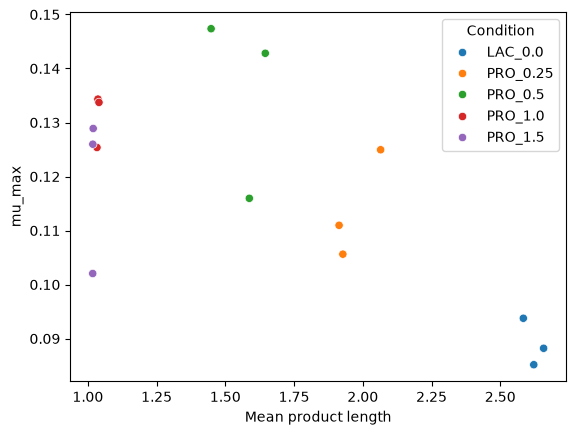

In [16]:
sns.scatterplot(data=mu_balch, x="Mean product length", 
                y="mu_max", hue="Condition")
plt.show()

# Panel H

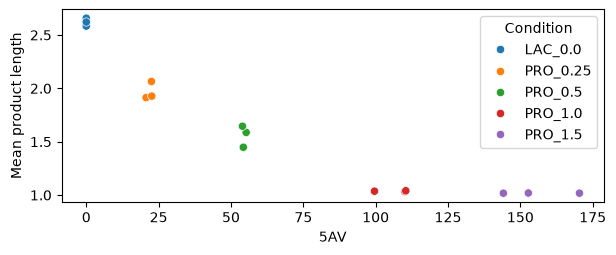

In [17]:
ava = (df_combined[(df_combined["Hour"] == 140) & (df_combined["Unit"] == "5-Aminovalerate")]
       [["Condition", "Replicate", "Value"]]
       .rename(columns={"Value": "5AV"}))

mu_balch = mu_balch.merge(ava, on=["Condition", "Replicate"], how="left")

plt.figure(figsize=(7, 2.5))

sns.scatterplot(data=mu_balch, x="5AV", 
                y="Mean product length", hue="Condition")

plt.show()



## Panel I

In [18]:
df = pd.read_excel("Figure5.xlsx", sheet_name="PYRU_h2co2")
id_vars = ["Strain", "Condition", "Time", "Replicate"]

df_long = df.melt(
    id_vars=id_vars,
    value_vars=[c for c in df.columns if c not in id_vars],
    var_name="Unit",
    value_name="Value"
)

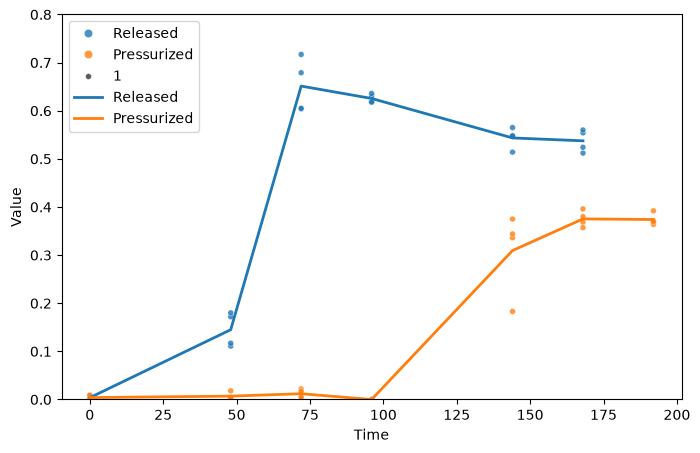

In [19]:
plotdata = df_long[df_long["Unit"].isin(["OD600"])]

summary = (
    plotdata.groupby(["Condition", "Time"])["Value"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

# replicates as points
sns.scatterplot(
    data=plotdata,
    x="Time",
    y="Value",
    hue="Condition",
    alpha=0.8,
    size=1,
    hue_order=["Released","Pressurized"]
)

# mean as line
sns.lineplot(
    data=summary,
    x="Time",
    y="Value",
    hue="Condition",
    linewidth=2,
    hue_order=["Released","Pressurized"]
)
plt.ylim(0, 0.8)
plt.legend()
plt.show()

## Panel J

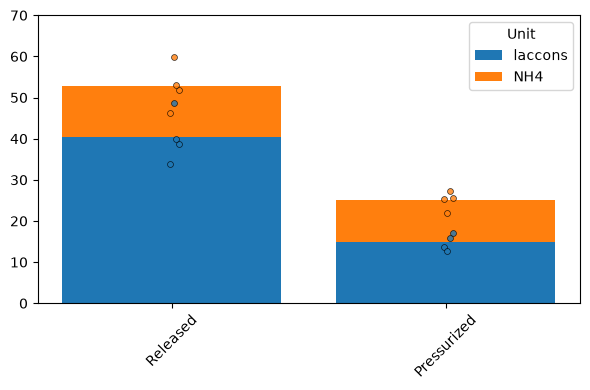

In [20]:
unit="NH4"
deamination = df_long[
    ((df_long["Unit"]==unit) & (df_long["Condition"]=="Pressurized") & (df_long["Time"]==192)) |
    ((df_long["Unit"]==unit) & (df_long["Condition"]=="Released") & (df_long["Time"]==168))]
unit="laccons"
laccons = df_long[
    ((df_long["Unit"]==unit) & (df_long["Condition"]=="Pressurized") & (df_long["Time"]==192)) |
    ((df_long["Unit"]==unit) & (df_long["Condition"]=="Released") & (df_long["Time"]==168))]
combined = pd.concat([deamination, laccons], ignore_index=True)


# i want lactate on bottom so fixing orders
cond_order=["Released","Pressurized"]
unit_order=["laccons","NH4"]

# take replicates to means
means = (
    combined
    .groupby(["Condition", "Unit"], as_index=False)["Value"]
    .mean()
)

means["Condition"] = pd.Categorical(means["Condition"], categories=cond_order, ordered=True)
means["Unit"] = pd.Categorical(means["Unit"], categories=unit_order, ordered=True)

means = means.sort_values(["Condition", "Unit"])

# stack means
means["y1"] = means.groupby("Condition")["Value"].cumsum()
means["y0"] = means["y1"] - means["Value"]


rep_stack = (
    combined
    .copy()
)

rep_stack["Condition"] = pd.Categorical(rep_stack["Condition"], categories=cond_order, ordered=True)
rep_stack["Unit"] = pd.Categorical(rep_stack["Unit"], categories=unit_order, ordered=True)

rep_stack = rep_stack.sort_values(["Condition", "Replicate", "Unit"])

# stack within each replicate
rep_stack["y1"] = rep_stack.groupby(["Condition", "Replicate"])["Value"].cumsum()
rep_stack["y0"] = rep_stack["y1"] - rep_stack["Value"]
rep_stack["stack_y"] = rep_stack["y1"]

# fix the deviation in x-direction so that replicate dots stack vertically
x_map = {c: i for i, c in enumerate(cond_order)}

means["x"] = means["Condition"].map(x_map).astype(float)
rep_stack["x"] = rep_stack["Condition"].map(x_map).astype(float)

# ibid
np.random.seed(42)
rep_offsets = {
    rep: np.random.uniform(-0.03, 0.03)
    for rep in rep_stack["Replicate"].unique()
}

rep_stack["x_jitter"] = rep_stack["x"] + rep_stack["Replicate"].map(rep_offsets)

# draw it
fig, ax = plt.subplots(figsize=(6, 4))

colors = plt.cm.tab10(range(len(unit_order)))

# 
for i, unit in enumerate(unit_order):
    sub = means[means["Unit"] == unit]
    ax.bar(
        sub["x"],
        sub["Value"],
        bottom=sub["y0"],
        color=colors[i],
        width=0.8,
        label=unit
    )

# --- replicate stacked points ---
for i, unit in enumerate(unit_order):
    subp = rep_stack[rep_stack["Unit"] == unit]

    ax.scatter(
        subp["x_jitter"].to_numpy(),
        subp["stack_y"].to_numpy(),
        facecolors=colors[i],
        edgecolors="black",
        linewidths=0.5,
        alpha=0.8,
        s=18
    )

# --- axes / legend ---
ax.set_xticks(list(x_map.values()))
ax.set_xticklabels(cond_order, rotation=45)
ax.set_ylim(0, 70)

ax.legend(title="Unit")

plt.tight_layout()
plt.show()

In [21]:
COEFF = {"C2": 1, "C4n": 2, "C6n": 3}

plotdata = df_long[
    df_long["Unit"].isin(COEFF)
    & (((df_long["Condition"] == "Pressurized") & (df_long["Time"] == 192))
       | ((df_long["Condition"] == "Released") & (df_long["Time"] == 168)))
]

combined = plotdata[plotdata["Value"] > 0].copy()
combined["as_accoa"] = combined["Value"] * combined["Unit"].map(COEFF)

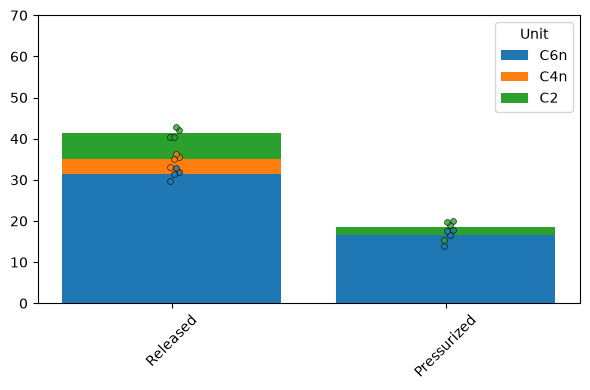

In [22]:
# we want C6 on bottom
unit_order = ["C6n","C4n","C2"]
cond_order = ["Released","Pressurized"]

# take replicates to means
means = (
    combined
    .groupby(["Condition", "Unit"], as_index=False)["as_accoa"]
    .mean()
)

means["Condition"] = pd.Categorical(means["Condition"], categories=cond_order, ordered=True)
means["Unit"] = pd.Categorical(means["Unit"], categories=unit_order, ordered=True)

means = means.sort_values(["Condition", "Unit"])

# stack means
means["y1"] = means.groupby("Condition")["as_accoa"].cumsum()
means["y0"] = means["y1"] - means["as_accoa"]


rep_stack = (
    combined
    .copy()
)

rep_stack["Condition"] = pd.Categorical(rep_stack["Condition"], categories=cond_order, ordered=True)
rep_stack["Unit"] = pd.Categorical(rep_stack["Unit"], categories=unit_order, ordered=True)

rep_stack = rep_stack.sort_values(["Condition", "Replicate", "Unit"])

# stack within each replicate
rep_stack["y1"] = rep_stack.groupby(["Condition", "Replicate"])["as_accoa"].cumsum()
rep_stack["y0"] = rep_stack["y1"] - rep_stack["as_accoa"]
rep_stack["stack_y"] = rep_stack["y1"]

# fix the deviation in x-direction so that replicate dots stack vertically
x_map = {c: i for i, c in enumerate(cond_order)}

means["x"] = means["Condition"].map(x_map).astype(float)
rep_stack["x"] = rep_stack["Condition"].map(x_map).astype(float)

# ibid
np.random.seed(42)
rep_offsets = {
    rep: np.random.uniform(-0.03, 0.03)
    for rep in rep_stack["Replicate"].unique()
}

rep_stack["x_jitter"] = rep_stack["x"] + rep_stack["Replicate"].map(rep_offsets)

fig, ax = plt.subplots(figsize=(6, 4))

colors = plt.cm.tab10(range(len(unit_order)))

# 
for i, unit in enumerate(unit_order):
    sub = means[means["Unit"] == unit]
    ax.bar(
        sub["x"],
        sub["as_accoa"],
        bottom=sub["y0"],
        color=colors[i],
        width=0.8,
        label=unit
    )

for i, unit in enumerate(unit_order):
    subp = rep_stack[rep_stack["Unit"] == unit]

    ax.scatter(
        subp["x_jitter"].to_numpy(),
        subp["stack_y"].to_numpy(),
        facecolors=colors[i],
        edgecolors="black",
        linewidths=0.5,
        alpha=0.8,
        s=18
    )

ax.set_xticks(list(x_map.values()))
ax.set_xticklabels(cond_order, rotation=45)
ax.set_ylim(0, 70)

ax.legend(title="Unit")

plt.tight_layout()
plt.show()

## Panel K

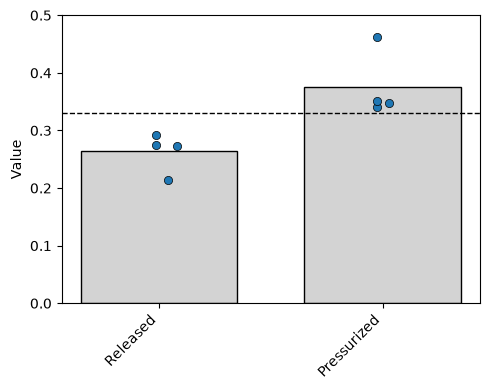

In [23]:
KEY = ["Condition", "Time", "Replicate"]

w = combined.pivot_table(index=KEY, columns="Unit",
                         values=["Value", "as_accoa"], fill_value=0)

mpl = w["as_accoa"].sum(axis=1) / w["Value"].sum(axis=1)

laccons = laccons.merge(
    pd.DataFrame({"mean_product_length": mpl, "c6": w[("Value", "C6n")]}).reset_index(),
    on=KEY, how="left",
)
laccons["yield_c6_lac"] = laccons["c6"] / laccons["Value"]
laccons = laccons.drop(columns="c6")

condition_order = ["Released", "Pressurized"]

laccons["Condition"] = pd.Categorical(
    laccons["Condition"],
    categories=condition_order,
    ordered=True,
)

# get means
summary = (
    laccons
    .groupby("Condition", observed=True, as_index=False)
    .agg(mean_val=("yield_c6_lac", "mean"))
    .set_index("Condition")
    .reindex(condition_order)
)

fig, ax = plt.subplots(figsize=(5, 4))

x = np.arange(len(condition_order))

# averages as bars
ax.bar(
    x,
    summary["mean_val"],
    color="lightgray",
    edgecolor="black",
    width=0.7,
    zorder=1,
)

# replicates as points
for i, handling in enumerate(condition_order):

    vals = laccons.loc[
        laccons["Condition"] == handling,
        "yield_c6_lac"
    ].values

    jitter = np.random.normal(0, 0.05, len(vals))

    ax.scatter(
        np.full(len(vals), x[i]) + jitter,
        vals,
        color="tab:blue",
        edgecolor="black",
        linewidth=0.5,
        s=35,
        zorder=3,
    )

ax.set_xticks(x)
ax.set_xticklabels(condition_order, rotation=45, ha="right")
ax.axhline(0.33, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("Value")
ax.set_ylim(0, 0.5)

plt.tight_layout()
plt.show()


## Panel L

In [24]:
df = pd.read_excel("Figure5.xlsx",sheet_name="electron_carrier_balance_h2ase", 
                   skiprows=1, skipfooter=2, # i left notes here which we need to remove
                   usecols=['Strain', 'Handling', 'molH2/molS', 'MPL'])

oct = df[df["Strain"]=="octanoica"]
pyru = df[df["Strain"]=="pyruvativorans"]

slope, intercept, r_value, p_value, std_err = stats.linregress(oct["molH2/molS"].to_numpy(), oct["MPL"].to_numpy())
r_squared = r_value**2
print(f"P. octanoica H2 / substrates\np-value: {p_value} \nR^2: {r_squared}")

slope, intercept, r_value, p_value, std_err = stats.linregress(pyru["molH2/molS"].to_numpy(), pyru["MPL"].to_numpy())
r_squared = r_value**2
print(f"P. pyruvativorans H2 / substrates\np-value: {p_value} \nR^2: {r_squared}")


P. octanoica H2 / substrates
p-value: 0.0035641111247442627 
R^2: 0.8422555490594281
P. pyruvativorans H2 / substrates
p-value: 0.07058685099731227 
R^2: 0.4453699163541081


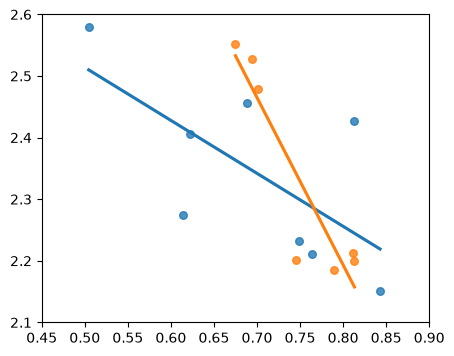

In [25]:
fig, ax = plt.subplots(figsize=(5, 4))

sns.regplot(
    x=pyru["molH2/molS"].to_numpy(), y=pyru["MPL"].to_numpy(), ci=None,
    scatter_kws={"s": 30},
    line_kws={"color": "tab:blue"},
    ax=ax,
)

sns.regplot(
    x=oct["molH2/molS"].to_numpy(), y=oct["MPL"].to_numpy(), ci=None,
    scatter_kws={"s": 30},
    line_kws={"color": "tab:orange"},
    ax=ax,
)

plt.ylim([2.1, 2.6])
plt.xlim([0.45, 0.9])
plt.show()